# 04 — Demand Forecasting

**Project:** Sigmoid Bike-Sharing Case Study

**Objective:** Build and evaluate a demand-prediction model using a chronological split. The goal is to estimate expected completed rentals by hour and assess whether forecasts could support better bike allocation.

**Important:** The dataset records completed rentals (`cnt`), not failed rental attempts or station-level inventory. A good prediction model can help anticipate observed demand, but it cannot prove that bikes were unavailable.

## 1. Import libraries

In [1]:
from pathlib import Path
import tkinter as tk
from tkinter import filedialog

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 2. Locate the project and load the hourly dataset
This cell searches the current folder and its parents first. If the project folder is not found, it opens a folder picker.

In [2]:
def find_project_folder():
    locations = [Path.cwd(), *Path.cwd().parents]
    for location in locations:
        if (location / "data" / "hour.csv").exists():
            return location

    common_locations = [
        Path.home() / "Documents" / "Sigmoid_Bike_Sharing_Case_Study",
        Path.home() / "Desktop" / "Sigmoid_Bike_Sharing_Case_Study",
        Path.home() / "Downloads" / "Sigmoid_Bike_Sharing_Case_Study",
    ]
    for location in common_locations:
        if (location / "data" / "hour.csv").exists():
            return location

    root = tk.Tk()
    root.withdraw()
    selected = filedialog.askdirectory(
        title="Select Sigmoid_Bike_Sharing_Case_Study folder"
    )
    root.destroy()

    if selected:
        location = Path(selected)
        if (location / "data" / "hour.csv").exists():
            return location

    raise FileNotFoundError(
        "Could not find data/hour.csv. Select the project folder containing data/hour.csv."
    )


BASE_DIR = find_project_folder()
DATA_DIR = BASE_DIR / "data"

hour_df = pd.read_csv(DATA_DIR / "hour.csv", parse_dates=["dteday"])
hour_work = hour_df.copy()

print("Project folder:", BASE_DIR)
print("Hourly dataset shape:", hour_work.shape)
display(hour_work.head())

Project folder: C:\Users\prasa\Documents\Sigmoid_Bike_Sharing_Case_Study
Hourly dataset shape: (17379, 17)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


## 3. Prepare data for modelling
We sort observations by time and retain only variables available as predictors. `cnt`, `casual`, and `registered` are outcomes and must not be used as input features.

In [3]:
hour_work = hour_work.sort_values(["dteday", "hr"]).reset_index(drop=True)

hour_work["year"] = hour_work["dteday"].dt.year
hour_work["month"] = hour_work["dteday"].dt.month
hour_work["day"] = hour_work["dteday"].dt.day
hour_work["dayofweek"] = hour_work["dteday"].dt.dayofweek

FEATURE_COLUMNS = [
    "season", "yr", "mnth", "hr", "holiday", "weekday",
    "workingday", "weathersit", "temp", "atemp", "hum",
    "windspeed", "year", "month", "day", "dayofweek"
]
TARGET_COLUMN = "cnt"

model_data = hour_work[FEATURE_COLUMNS + [TARGET_COLUMN, "dteday"]].copy()
model_data = model_data.dropna(subset=FEATURE_COLUMNS + [TARGET_COLUMN])

print("Rows available for modelling:", len(model_data))
print("Date range:", model_data["dteday"].min(), "to", model_data["dteday"].max())
print("Missing values in model data:", int(model_data[FEATURE_COLUMNS + [TARGET_COLUMN]].isna().sum().sum()))

Rows available for modelling: 17379
Date range: 2011-01-01 00:00:00 to 2012-12-31 00:00:00
Missing values in model data: 0


C:\Users\prasa\AppData\Local\Temp\ipykernel_34980\1544139494.py:6: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  hour_work["dayofweek"] = hour_work["dteday"].dt.dayofweek


## 4. Chronological train, validation and test split
Do not randomly shuffle time-series observations. The earliest 70% is used for training, the next 15% for validation, and the latest 15% for final testing.

In [4]:
n_rows = len(model_data)
train_end = int(n_rows * 0.70)
validation_end = int(n_rows * 0.85)

train_data = model_data.iloc[:train_end].copy()
validation_data = model_data.iloc[train_end:validation_end].copy()
test_data = model_data.iloc[validation_end:].copy()

print("Train:", len(train_data), train_data["dteday"].min(), "to", train_data["dteday"].max())
print("Validation:", len(validation_data), validation_data["dteday"].min(), "to", validation_data["dteday"].max())
print("Test:", len(test_data), test_data["dteday"].min(), "to", test_data["dteday"].max())

X_train = train_data[FEATURE_COLUMNS]
y_train = train_data[TARGET_COLUMN]

X_validation = validation_data[FEATURE_COLUMNS]
y_validation = validation_data[TARGET_COLUMN]

X_test = test_data[FEATURE_COLUMNS]
y_test = test_data[TARGET_COLUMN]

Train: 12165 2011-01-01 00:00:00 to 2012-05-27 00:00:00
Validation: 2607 2012-05-27 00:00:00 to 2012-09-12 00:00:00
Test: 2607 2012-09-12 00:00:00 to 2012-12-31 00:00:00


## 5. Define evaluation metrics
MAE is the average absolute prediction error in rentals. RMSE penalises larger errors more strongly. R² measures the proportion of target variance explained by the model.

In [5]:
def evaluate_regression(y_true, y_pred, model_name):
    return {
        "model": model_name,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }

## 6. Baseline model — average demand by hour and working-day status
A baseline is necessary: a complex model is useful only if it improves on a simple, sensible benchmark.

In [6]:
baseline_table = (
    train_data.groupby(["hr", "workingday"])["cnt"]
    .mean()
    .rename("baseline_prediction")
    .reset_index()
)

validation_baseline = validation_data.merge(
    baseline_table,
    on=["hr", "workingday"],
    how="left"
)

fallback_mean = y_train.mean()
validation_baseline["baseline_prediction"] = (
    validation_baseline["baseline_prediction"].fillna(fallback_mean)
)

baseline_validation_metrics = evaluate_regression(
    y_validation,
    validation_baseline["baseline_prediction"],
    "Hourly + working-day mean baseline"
)

display(pd.DataFrame([baseline_validation_metrics]))

,model,MAE,RMSE,R2
0,Hourly + working-day mean baseline,125.933311,167.151129,0.439344


## 7. Train a Random Forest model
We use one-hot encoding for categorical predictors. The encoding is learned from the training set only, then aligned to validation and test columns.

In [7]:
CATEGORICAL_COLUMNS = [
    "season", "yr", "mnth", "hr", "holiday", "weekday",
    "workingday", "weathersit", "year", "month", "day", "dayofweek"
]
NUMERIC_COLUMNS = ["temp", "atemp", "hum", "windspeed"]

def make_model_matrix(data):
    categorical = pd.get_dummies(
        data[CATEGORICAL_COLUMNS].astype("category"),
        columns=CATEGORICAL_COLUMNS,
        dtype=int
    )
    numeric = data[NUMERIC_COLUMNS].reset_index(drop=True)
    return pd.concat([numeric, categorical.reset_index(drop=True)], axis=1)

X_train_encoded = make_model_matrix(X_train)
X_validation_encoded = make_model_matrix(X_validation)
X_test_encoded = make_model_matrix(X_test)

X_validation_encoded = X_validation_encoded.reindex(
    columns=X_train_encoded.columns, fill_value=0
)
X_test_encoded = X_test_encoded.reindex(
    columns=X_train_encoded.columns, fill_value=0
)

random_forest = RandomForestRegressor(
    n_estimators=300,
    min_samples_leaf=2,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

random_forest.fit(X_train_encoded, y_train)

validation_predictions = random_forest.predict(X_validation_encoded)

rf_validation_metrics = evaluate_regression(
    y_validation, validation_predictions, "Random Forest"
)

validation_comparison = pd.DataFrame([
    baseline_validation_metrics,
    rf_validation_metrics
])

display(validation_comparison)

,model,MAE,RMSE,R2
0,Hourly + working-day mean baseline,125.933311,167.151129,0.439344
1,Random Forest,99.127478,140.250183,0.605284


## 8. Compare validation performance
Use the validation results to decide whether the Random Forest is worth carrying forward. Do not use the test set to choose the model.

In [8]:
validation_comparison = validation_comparison.sort_values("MAE")
display(validation_comparison)

best_model_name = validation_comparison.iloc[0]["model"]
print("Best validation model:", best_model_name)

,model,MAE,RMSE,R2
1,Random Forest,99.127478,140.250183,0.605284
0,Hourly + working-day mean baseline,125.933311,167.151129,0.439344


Best validation model: Random Forest


## 9. Final evaluation on the untouched test period
After model choice, evaluate on the latest time period. This is the most realistic estimate of performance on future observations from this dataset.

In [9]:
if best_model_name == "Random Forest":
    final_test_predictions = random_forest.predict(X_test_encoded)
else:
    test_baseline = test_data.merge(
        baseline_table, on=["hr", "workingday"], how="left"
    )
    final_test_predictions = test_baseline["baseline_prediction"].fillna(
        fallback_mean
    ).to_numpy()

test_metrics = evaluate_regression(
    y_test, final_test_predictions, best_model_name
)

display(pd.DataFrame([test_metrics]))

,model,MAE,RMSE,R2
0,Random Forest,64.091353,94.541807,0.80682


## 10. Actual vs predicted demand

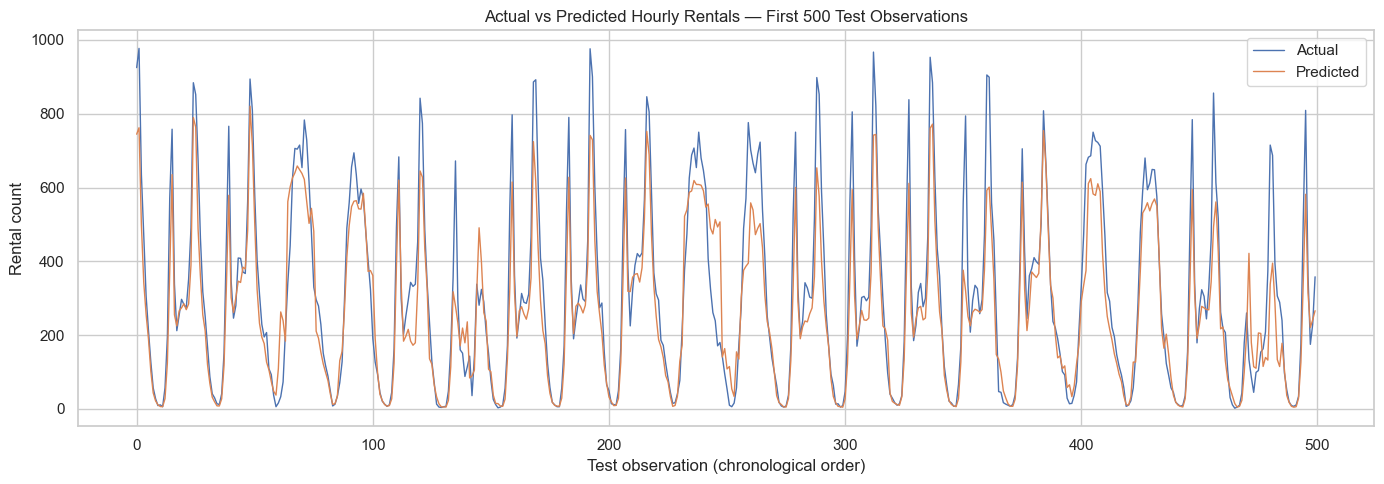

In [10]:
comparison_df = pd.DataFrame({
    "date": test_data["dteday"].to_numpy(),
    "actual": y_test.to_numpy(),
    "predicted": final_test_predictions
})

sample_size = min(500, len(comparison_df))
plot_sample = comparison_df.iloc[:sample_size]

plt.figure(figsize=(14, 5))
plt.plot(plot_sample["actual"].to_numpy(), label="Actual", linewidth=1)
plt.plot(plot_sample["predicted"].to_numpy(), label="Predicted", linewidth=1)
plt.title(f"Actual vs Predicted Hourly Rentals — First {sample_size} Test Observations")
plt.xlabel("Test observation (chronological order)")
plt.ylabel("Rental count")
plt.legend()
plt.tight_layout()
plt.show()

## 11. Residual analysis
Residual = actual demand − predicted demand. Look for systematic underprediction, overprediction, or errors that grow at high-demand periods.

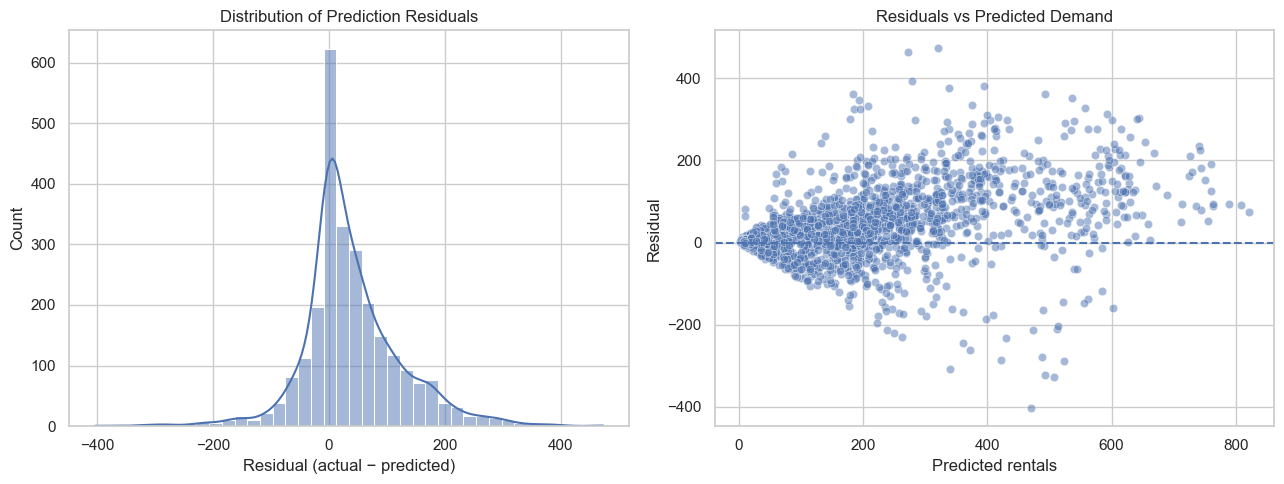

Mean residual: 39.67


In [11]:
comparison_df["residual"] = comparison_df["actual"] - comparison_df["predicted"]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(comparison_df["residual"], bins=40, kde=True, ax=axes[0])
axes[0].set_title("Distribution of Prediction Residuals")
axes[0].set_xlabel("Residual (actual − predicted)")

sns.scatterplot(
    data=comparison_df.sample(min(2000, len(comparison_df)), random_state=RANDOM_STATE),
    x="predicted", y="residual", alpha=0.5, ax=axes[1]
)
axes[1].axhline(0, linestyle="--")
axes[1].set_title("Residuals vs Predicted Demand")
axes[1].set_xlabel("Predicted rentals")
axes[1].set_ylabel("Residual")

plt.tight_layout()
plt.show()

print("Mean residual:", round(comparison_df["residual"].mean(), 2))

## 12. Feature importance
Feature importance indicates which encoded inputs the fitted Random Forest relied on most. It describes model behaviour, not causation.

,feature,importance
1,atemp,0.148336
39,hr_17,0.093780
2,hum,0.085378
40,hr_18,0.081350
0,temp,0.060156
30,hr_8,0.059050
56,workingday_1,0.043794
55,workingday_0,0.041525
41,hr_19,0.028958
8,yr_0,0.019566


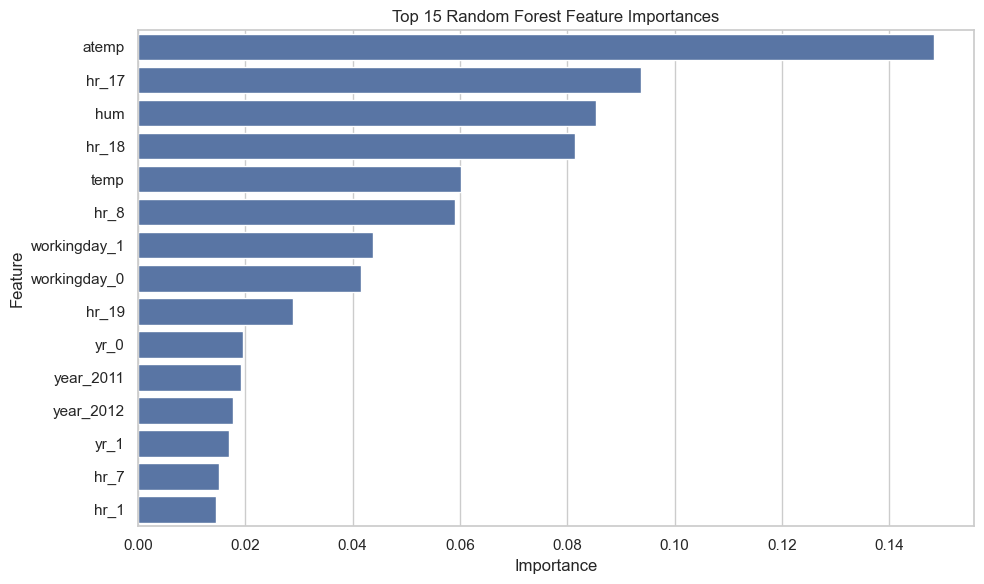

In [12]:
feature_importance = (
    pd.DataFrame({
        "feature": X_train_encoded.columns,
        "importance": random_forest.feature_importances_
    })
    .sort_values("importance", ascending=False)
)

display(feature_importance.head(15))

plt.figure(figsize=(10, 6))
sns.barplot(
    data=feature_importance.head(15),
    x="importance", y="feature"
)
plt.title("Top 15 Random Forest Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

## 13. Forecasting limitations and business interpretation

### What this model can support
- Estimating expected hourly completed rentals from calendar, weather and time features.
- Identifying periods where demand is predictably high.
- Supporting a pilot that tests whether forecast-informed bike redistribution improves availability.

### What this model cannot establish
- Whether a customer failed to rent because no bike was available.
- Which station needs additional bikes, because station-level inventory and location are not included.
- Whether buying more bikes is better than redistributing existing bikes.

### Important modelling limitation
This is a supervised prediction exercise on historical hourly records, not a full operational time-series forecasting system. The weather and calendar predictors are assumed to be known at prediction time. In a real deployment, future weather would need to come from a forecast source, and evaluation should simulate that availability.

## 14. Save the test predictions and model results
The outputs are saved inside the project's `outputs` folder. This cell creates the folder if it does not exist.

In [13]:
OUTPUT_DIR = BASE_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

prediction_output = comparison_df.copy()
prediction_output.to_csv(
    OUTPUT_DIR / "hourly_demand_test_predictions.csv",
    index=False
)

pd.DataFrame([test_metrics]).to_csv(
    OUTPUT_DIR / "forecasting_test_metrics.csv",
    index=False
)

feature_importance.to_csv(
    OUTPUT_DIR / "random_forest_feature_importance.csv",
    index=False
)

print("Saved forecasting outputs to:", OUTPUT_DIR)

Saved forecasting outputs to: C:\Users\prasa\Documents\Sigmoid_Bike_Sharing_Case_Study\outputs


## 15. Key takeaways
Complete this section after running the notebook. Use the actual test metrics and plots rather than copying expected values from another project.

In [14]:
print("Selected model:", best_model_name)
print("Test MAE:", round(test_metrics["MAE"], 2))
print("Test RMSE:", round(test_metrics["RMSE"], 2))
print("Test R2:", round(test_metrics["R2"], 4))

print(
    "\nBusiness interpretation: forecasts can inform when demand is likely to be high, "
    "but inventory and failed-rental data are still required to decide where bikes are unavailable."
)

Selected model: Random Forest
Test MAE: 64.09
Test RMSE: 94.54
Test R2: 0.8068

Business interpretation: forecasts can inform when demand is likely to be high, but inventory and failed-rental data are still required to decide where bikes are unavailable.


## 16. Save the selected model and its exact preprocessing schema

This cell saves the model selected using validation data, together with the exact encoded feature-column order used during training. The Streamlit application uses this bundle to reproduce the same one-hot encoding at prediction time. The older 12-feature pickle is not overwritten.

In [ ]:
import joblib

MODEL_DIR = BASE_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

MODEL_BUNDLE_PATH = MODEL_DIR / "bike_demand_model_bundle.pkl"

if best_model_name == "Random Forest":
    selected_model = random_forest
    saved_feature_columns = list(X_train_encoded.columns)
    input_format = "onehot"
elif best_model_name == "Hourly + working-day mean baseline":
    selected_model = None
    saved_feature_columns = []
    input_format = "raw_lookup"
else:
    raise ValueError(f"Unsupported selected model: {best_model_name}")

model_bundle = {
    "model_name": str(best_model_name),
    "model": selected_model,
    "feature_columns": saved_feature_columns,
    "input_format": input_format,
    "baseline_table": baseline_table.copy(),
    "fallback_mean": float(fallback_mean),
    "metrics": {
        "MAE": float(test_metrics["MAE"]),
        "RMSE": float(test_metrics["RMSE"]),
        "R2": float(test_metrics["R2"]),
    },
    "split": {
        "train_rows": int(len(train_data)),
        "validation_rows": int(len(validation_data)),
        "test_rows": int(len(test_data)),
        "train_start": str(train_data["dteday"].min().date()),
        "train_end": str(train_data["dteday"].max().date()),
        "validation_start": str(validation_data["dteday"].min().date()),
        "validation_end": str(validation_data["dteday"].max().date()),
        "test_start": str(test_data["dteday"].min().date()),
        "test_end": str(test_data["dteday"].max().date()),
    },
    "target_column": TARGET_COLUMN,
    "raw_feature_columns": list(FEATURE_COLUMNS),
    "categorical_columns": list(CATEGORICAL_COLUMNS),
    "numeric_columns": list(NUMERIC_COLUMNS),
    "random_state": int(RANDOM_STATE),
}

joblib.dump(model_bundle, MODEL_BUNDLE_PATH)

print("Saved model bundle:", MODEL_BUNDLE_PATH)
print("Selected model:", model_bundle["model_name"])
print("Input format:", model_bundle["input_format"])
print("Encoded feature count:", len(model_bundle["feature_columns"]))
print("Test metrics:", model_bundle["metrics"])
